# Лекция 1: Введение в машинное обучение
## Практическая часть

В этом ноутбуке мы на коде разберём то, о чём говорили на слайдах:

1. **Модель, алгоритм и признаки**
2. **Датасет**
3. **Типы машинного обучения**

Запускайте ячейки по порядку. Все данные генерируются прямо здесь, ничего скачивать не нужно.

In [1]:
# @title
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.datasets import load_iris, make_blobs
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, mean_absolute_error, r2_score, ConfusionMatrixDisplay
from sklearn.inspection import DecisionBoundaryDisplay

plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

---
# 1. Модель, алгоритм и признаки

Вспомним три шага, которыми мы принимаем решения: **вспомнить → сформулировать правило → предсказать**.

## Пример 1. «Будет ли сегодня дождь?»

Наш *опыт* — погода за последние 10 дней.

In [ ]:
history = ["дождь", "дождь", "ясно", "дождь", "дождь",
           "дождь", "ясно", "дождь", "дождь", "дождь"]

def train_weather_model(history):
    """алгоритм"""
    rainy_days = history.count("дождь")                       # считаем дождливые дни
    verdict = "дождь" if rainy_days > len(history) / 2 else "ясно"   # каких дней больше?

    def model():
        """модель"""
        return verdict

    return model

weather_model = train_weather_model(history)   # алгоритм запускаем один раз...
print("Прогноз на сегодня:", weather_model())  # ...а пользуемся уже моделью

Прогноз на сегодня: дождь


**Что здесь что:**
- *алгоритм* — функция `train_weather_model` (рецепт);
- *модель* — функция `model` внутри неё (готовое блюдо);
- *данные* — список `history`.

## Пример 2. Спам

Теперь у каждого письма есть **признаки**, то есть свойства, по которым модель «смотрит» на письмо:
- `has_win_word` — есть ли слово «выигрыш»;
- `n_exclaims` — число восклицательных знаков;
- `n_links` — число ссылок.

`is_spam` — правильный ответ, который поставил человек.

In [4]:
emails = pd.DataFrame({
    "has_win_word": [1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0],
    "n_exclaims":   [5, 3, 6, 1, 7, 0, 2, 4, 0, 0, 6, 1],
    "n_links":      [4, 2, 3, 1, 5, 0, 1, 3, 0, 1, 6, 0],
    "is_spam":      [1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0],
})
emails

,has_win_word,n_exclaims,n_links,is_spam
0,1,5,4,1
1,1,3,2,1
2,0,6,3,1
3,0,1,1,0
4,1,7,5,1
5,0,0,0,0
6,0,2,1,0
7,1,4,3,1
8,0,0,0,0
9,0,0,1,0


Сначала **модель, написанная руками**: мы сами придумали правило.

In [5]:
def spam_model_by_hand(email):
    # если есть слово "выигрыш" и хотя бы 3 восклицательных знака — это спам
    return int(email["has_win_word"] == 1 and email["n_exclaims"] >= 3)

predictions = emails.apply(spam_model_by_hand, axis=1)
print("Точность модели, написанной руками:", accuracy_score(emails["is_spam"], predictions))

Точность модели, написанной руками: 0.9166666666666666


А теперь **алгоритм** найдёт правила сам. `DecisionTreeClassifier.fit(...)` — это и есть алгоритм, а то, что получилось после обучения, — модель.

In [6]:
features = ["has_win_word", "n_exclaims", "n_links"]

algorithm = DecisionTreeClassifier(max_depth=2, random_state=0)   # алгоритм
spam_model = algorithm.fit(emails[features], emails["is_spam"])   # после обучения получаем модель

print("Правила, которые алгоритм нашёл сам:\n")
print(export_text(spam_model, feature_names=features))
print("Точность:", accuracy_score(emails["is_spam"], spam_model.predict(emails[features])))

Правила, которые алгоритм нашёл сам:

|--- n_exclaims <= 2.50
|   |--- class: 0
|--- n_exclaims >  2.50
|   |--- class: 1

Точность: 1.0


In [7]:
# Используем модель на новом письме, которого она не видела
new_email = pd.DataFrame([{"has_win_word": 1, "n_exclaims": 8, "n_links": 2}])
print("Это спам?", bool(spam_model.predict(new_email)[0]))

Это спам? True


**Вывод:** модель смотрит на мир только через признаки. Если признаки подобраны плохо, никакой алгоритм не поможет.

> *Попробуйте:* уберите из `features` признак `n_exclaims` и посмотрите, как изменятся правила и точность.

---
# 2. Датасет

Датасет — это таблица: **строка = объект**, **столбец = признак**. Один из столбцов может быть **целевой переменной** — ответом, который мы хотим научиться предсказывать.

Сгенерируем датасет подержанных автомобилей. Цена будет зависеть от возраста, пробега и расхода, плюс случайный шум, как в реальной жизни.

In [8]:
rng = np.random.default_rng(42)
n = 300

year = rng.integers(2005, 2025, n)
mileage = np.clip((2025 - year) * rng.normal(13000, 4000, n), 2000, None).round(-2)
consumption = rng.normal(7.5, 1.5, n).round(1)

price = (30000
         - (2025 - year) * 900
         - mileage * 0.05
         - (consumption - 7.5) * 300
         + rng.normal(0, 1500, n))
price = price.clip(1500).round(-2)

cars = pd.DataFrame({
    "year": year,                 # год выпуска
    "mileage": mileage,           # пробег, км
    "consumption": consumption,   # расход, л/100 км
    "price": price,               # цена - целевая переменная
})
cars.head(10)

,year,mileage,consumption,price
0,2006,328000.0,9.2,1500.0
1,2020,68100.0,8.1,20600.0
2,2018,86600.0,7.3,19400.0
3,2013,106300.0,8.0,13300.0
4,2013,75600.0,10.4,13000.0
5,2022,33200.0,10.6,27800.0
6,2006,242900.0,7.6,3400.0
7,2018,140500.0,7.7,18300.0
8,2009,216300.0,9.1,2900.0
9,2006,321700.0,6.2,1500.0


In [9]:
print("Размер датасета (объектов, столбцов):", cars.shape)
cars.describe().round(1)

Размер датасета (объектов, столбцов): (300, 4)


,year,mileage,consumption,price
count,300.0,300.0,300.0,300.0
mean,2014.5,137736.3,7.4,14031.0
std,5.5,84934.7,1.5,8433.5
min,2005.0,7300.0,3.1,1500.0
25%,2010.0,69750.0,6.3,7100.0
50%,2014.0,123600.0,7.4,13800.0
75%,2019.0,200500.0,8.4,21200.0
max,2024.0,377800.0,11.4,30300.0


## Признаки и целевая переменная

Разделяем таблицу на `X` (признаки) и `y` (ответ).

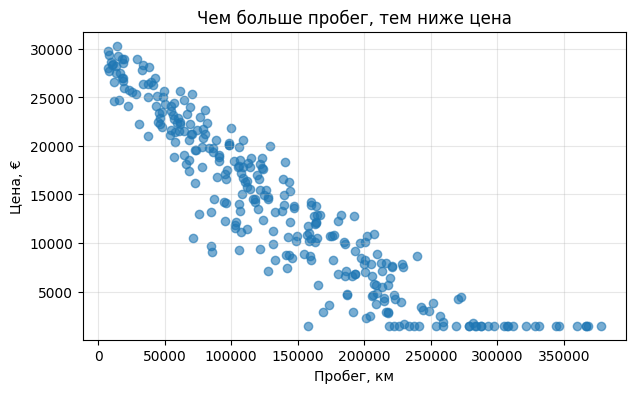

In [10]:
feature_names = ["year", "mileage", "consumption"]
X = cars[feature_names]
y = cars["price"]

plt.scatter(cars["mileage"], cars["price"], alpha=0.6)
plt.xlabel("Пробег, км")
plt.ylabel("Цена, €")
plt.title("Чем больше пробег, тем ниже цена")
plt.show()

## Обучающая и тестовая выборки

Как учебник и экзамен: учимся на одной части данных, проверяем на другой, которую модель не видела.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Для обучения:", len(X_train), "объектов")
print("Для проверки:", len(X_test), "объектов")

Для обучения: 240 объектов
Для проверки: 60 объектов


> **Мусор на входе — мусор на выходе.** Если в данных ошибки или перекосы, модель их выучит.
>
> *Попробуйте:* добавьте в `cars` несколько строк с ценой `1` и посмотрите, как это испортит модель в следующем разделе.

---
# 3. Типы машинного обучения

Три основных типа:
- **с учителем** (есть правильные ответы): классификация и регрессия;
- **без учителя** (ответов нет): кластеризация;
- **с подкреплением** (агент получает награду).

## 3.1. Обучение с учителем: классификация

Ответ — **категория**. Классический датасет: по размерам цветка определяем вид ириса.

In [12]:
iris = load_iris(as_frame=True)
X_iris, y_iris = iris.data, iris.target
print("Признаки:", list(X_iris.columns))
print("Классы:", iris.target_names.tolist())

Xi_train, Xi_test, yi_train, yi_test = train_test_split(
    X_iris, y_iris, test_size=0.2, random_state=42, stratify=y_iris
)

clf = KNeighborsClassifier(n_neighbors=5).fit(Xi_train, yi_train)
print("\nТочность на тестовой выборке:", round(accuracy_score(yi_test, clf.predict(Xi_test)), 3))

Признаки: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Классы: ['setosa', 'versicolor', 'virginica']

Точность на тестовой выборке: 1.0


In [13]:
# Новый цветок: длина и ширина чашелистика, длина и ширина лепестка
flower = pd.DataFrame([[5.0, 3.4, 1.5, 0.2]], columns=X_iris.columns)
print("Это:", iris.target_names[clf.predict(flower)[0]])

Это: setosa


### Графики: как модель видит классы

Сначала посмотрим на данные. Возьмём два признака лепестка: длину и ширину.

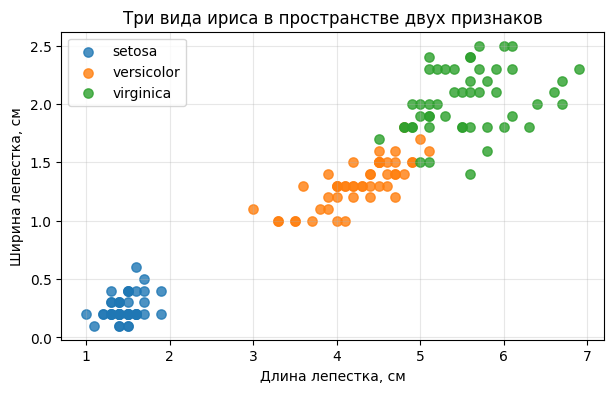

In [14]:
pc, pw = "petal length (cm)", "petal width (cm)"

fig, ax = plt.subplots()
for cls, name in enumerate(iris.target_names):
    m = y_iris == cls
    ax.scatter(X_iris.loc[m, pc], X_iris.loc[m, pw], label=name, alpha=0.8, s=45)
ax.set_xlabel("Длина лепестка, см")
ax.set_ylabel("Ширина лепестка, см")
ax.set_title("Три вида ириса в пространстве двух признаков")
ax.legend()
plt.show()

Теперь **граница решений**: обучим модель только на этих двух признаках и закрасим плоскость цветом того класса, который модель предсказывает в каждой точке. Точки с чёрной обводкой — тестовые цветки, которых модель не видела.

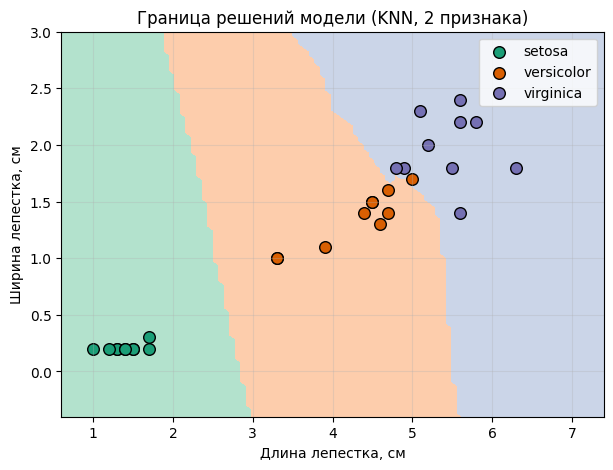

In [15]:
two = [pc, pw]
clf2 = KNeighborsClassifier(n_neighbors=5).fit(Xi_train[two], yi_train)

dark = ["#1b9e77", "#d95f02", "#7570b3"]            # цвета точек
light = ListedColormap(["#b3e2cd", "#fdcdac", "#cbd5e8"])   # те же цвета, но бледные: фон области класса

fig, ax = plt.subplots(figsize=(7, 5))
DecisionBoundaryDisplay.from_estimator(
    clf2, Xi_train[two], response_method="predict", cmap=light, eps=0.5, ax=ax,
    xlabel="Длина лепестка, см", ylabel="Ширина лепестка, см",
)
for cls, name in enumerate(iris.target_names):
    m = (yi_test == cls).to_numpy()
    ax.scatter(Xi_test[two][m][pc], Xi_test[two][m][pw], color=dark[cls], edgecolor="k", s=70, label=name)
ax.set_title("Граница решений модели (KNN, 2 признака)")
ax.legend()
plt.show()

И наконец **матрица ошибок** для модели на всех четырёх признаках: по строкам — реальный вид, по столбцам — предсказанный. Всё, что вне диагонали, — ошибки.

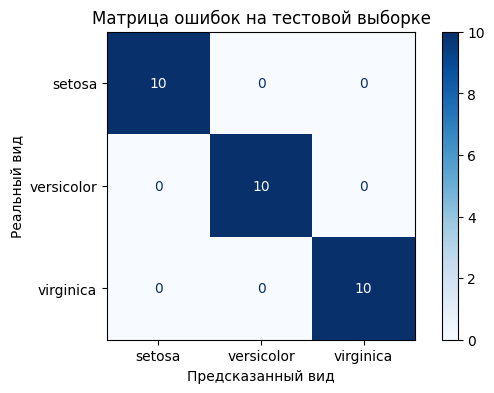

In [16]:
disp = ConfusionMatrixDisplay.from_estimator(clf, Xi_test, yi_test, display_labels=iris.target_names, cmap="Blues")
disp.ax_.set(title="Матрица ошибок на тестовой выборке", xlabel="Предсказанный вид", ylabel="Реальный вид")
disp.ax_.grid(False)
plt.show()

## 3.2. Обучение с учителем: регрессия

Ответ — **число**. Предсказываем цену автомобиля из нашего датасета.

In [17]:
reg = LinearRegression().fit(X_train, y_train)
pred = reg.predict(X_test)

print("Средняя ошибка (MAE): ", round(mean_absolute_error(y_test, pred)), "€")
print("Качество R²:          ", round(r2_score(y_test, pred), 3))

print("\nВклад каждого признака в цену:")
for name, coef in zip(feature_names, reg.coef_):
    print(f"  {name:12s} {coef:+.2f}")

Средняя ошибка (MAE):  1300 €
Качество R²:           0.963

Вклад каждого признака в цену:
  year         +966.28
  mileage      -0.04
  consumption  -392.95


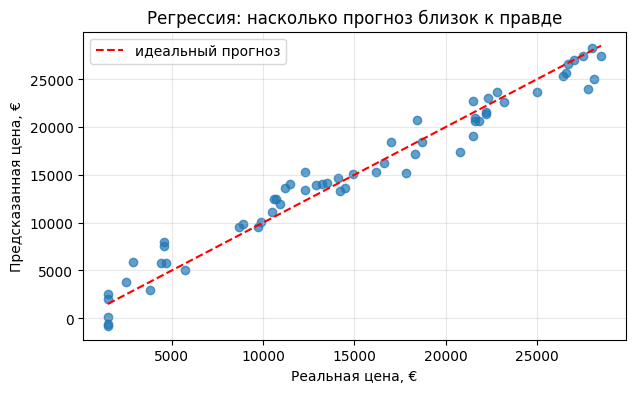

In [18]:
plt.scatter(y_test, pred, alpha=0.7)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, "r--", label="идеальный прогноз")
plt.xlabel("Реальная цена, €")
plt.ylabel("Предсказанная цена, €")
plt.title("Регрессия: насколько прогноз близок к правде")
plt.legend()
plt.show()

## 3.3. Обучение без учителя: кластеризация

Правильных ответов **нет**. У магазина есть покупатели, а группы мы не знаем. Пусть алгоритм найдёт их сам.

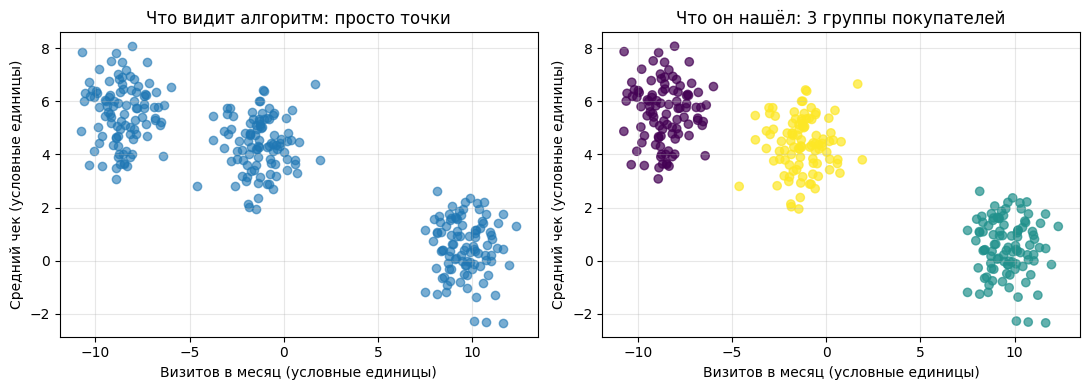

In [19]:
customers, _ = make_blobs(n_samples=300, centers=3, cluster_std=1.1, random_state=7)
customers = pd.DataFrame(customers, columns=["visits_per_month", "avg_check"])

kmeans = KMeans(n_clusters=3, n_init=10, random_state=0).fit(customers)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(customers["visits_per_month"], customers["avg_check"], alpha=0.6)
axes[0].set_title("Что видит алгоритм: просто точки")
axes[1].scatter(customers["visits_per_month"], customers["avg_check"], c=kmeans.labels_, cmap="viridis", alpha=0.7)
axes[1].set_title("Что он нашёл: 3 группы покупателей")
for ax in axes:
    ax.set_xlabel("Визитов в месяц (условные единицы)")
    ax.set_ylabel("Средний чек (условные единицы)")
plt.tight_layout()
plt.show()

## 3.4. Обучение с подкреплением

Нет готового датасета. **Агент** действует в **среде** и получает **награду**.

Простейший пример: коридор из 6 клеток. Агент стартует в клетке 0, награда (+1) лежит в клетке 5. Агент не знает правил, он пробует ходить влево или вправо и запоминает, какие действия приводили к награде (это называется Q-обучением).

In [20]:
n_states = 6              # клетки 0..5, цель в клетке 5
actions = [-1, +1]       # 0 = влево, 1 = вправо
Q = np.zeros((n_states, 2))          # «таблица ценности» действий
alpha, gamma, eps = 0.5, 0.9, 0.2    # скорость обучения, забывание будущего, доля случайных ходов
rng = np.random.default_rng(0)

for episode in range(300):
    s = 0
    for step in range(100):
        if rng.random() < eps:
            a = int(rng.integers(2))                                   # иногда пробуем наугад
        else:
            best = np.flatnonzero(Q[s] == Q[s].max())
            a = int(rng.choice(best))                                  # обычно берём лучшее из известного
        s_next = min(max(s + actions[a], 0), n_states - 1)
        reward = 1.0 if s_next == n_states - 1 else 0.0
        Q[s, a] += alpha * (reward + gamma * Q[s_next].max() - Q[s, a])
        s = s_next
        if s == n_states - 1:
            break

policy = ["→" if Q[s, 1] > Q[s, 0] else "←" for s in range(n_states - 1)]
print("Таблица ценности (столбцы: влево, вправо):")
print(Q.round(2))
print("\nЧему агент научился (в клетках 0–4):", " ".join(policy), "  [цель]")

Таблица ценности (столбцы: влево, вправо):
[[0.59 0.66]
 [0.59 0.73]
 [0.66 0.81]
 [0.73 0.9 ]
 [0.81 1.  ]
 [0.   0.  ]]

Чему агент научился (в клетках 0–4): → → → → →   [цель]


Агент сам, без единого размеченного примера, понял, что идти надо вправо. Так же, только в гораздо более сложной среде, обучали AlphaGo.

# Итоги

| Понятие | В нашем ноутбуке |
|---|---|
| Алгоритм | `LogisticRegression.fit`, `DecisionTreeClassifier.fit`, `LinearRegression.fit`, `KMeans.fit`, Q-обучение |
| Модель | то, что получилось после обучения: `exam_model`, `spam_model`, `reg`, `kmeans` |
| Признаки | столбцы `year`, `mileage`, `consumption` |
| Датасет | таблица `cars` и её разделение на train / test |
| Типы МО | классификация, регрессия, кластеризация, обучение с подкреплением |

## Задания для самостоятельной работы
1. Добавьте в датасет признак «объём двигателя» и проверьте, улучшилась ли модель.
2. Замените `LinearRegression` на `DecisionTreeRegressor` и сравните ошибки.
3. Измените `n_clusters` в кластеризации на 2 и на 5. Как изменится картинка?
4. Поменяйте `n_neighbors` в KNN на 1 и на 25 и посмотрите, как изменится граница решений на графике.
